# DSC 411/511 Project
# Notebook 04: RQ2: Can We Flag Large Losses Before the Adjuster Arrives?

**Class topics:** Lecture 07 (imbalanced targets: "Luxury = top 10%", confusion matrix, precision,
recall, moving the threshold, ROC, fixing imbalance), Lecture 05 (trees), Lecture 04 (feature ranking).

---

> **RQ2. Can we flag claims whose building damage is above a "large loss" line, using only facts known
> about the building, the policy and the storm?**

**Why it matters.** After a hurricane, thousands of claims arrive in a few days. The few very large losses
need the most experienced adjusters, early advance payments, and often a substantial-damage decision
(which triggers rebuilding rules and Increased Cost of Compliance coverage). A good flag at filing time
would help to send the right adjuster to the right house first.

---
# Section 0: Setup

In [1]:
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
                             precision_score, recall_score, f1_score)
import lightgbm as lgb
import shap

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
large_loss_line = json.load(open(TABLE_DIR / 'large_loss_definition.json'))['large_loss_line_usd']
print(f'Large-loss line from notebook 01: ${large_loss_line:,.0f}')

Large-loss line from notebook 01: $143,214


---
# Section 1: Where Should the "Large Loss" Line Be?

## 1.1 Damage, not payment

We define the line on **building damage** (`buildingDamageAmount`), not on the payment. The payment is
damage minus the deductible, cut off at the coverage limit (250,000 dollars for most homes). So a payment
line would partly measure the **policy**, not the **flood**. Damage measures the physical loss.

## 1.2 Looking at the distribution (training years only)

In [2]:
damage_known = claims[claims['buildingDamageAmount'].notna()].copy()
train_damage = damage_known.loc[damage_known['loss_year'].isin(TRAIN_YEARS), 'buildingDamageAmount']
positive_train_damage = train_damage[train_damage > 0]
percentile_table = pd.DataFrame({'percentile': [50, 75, 80, 90, 95, 99]})
percentile_table['damage_usd'] = [positive_train_damage.quantile(p / 100) for p in percentile_table['percentile']]
total_damage = positive_train_damage.sum()
percentile_table['share_of_all_damage_above_%'] = [positive_train_damage[positive_train_damage > v].sum() / total_damage * 100
                                                   for v in percentile_table['damage_usd']]
print(f'Positive-damage claims 2020-2023: {len(positive_train_damage):,}')
print(percentile_table.round(1).to_string(index=False))

Positive-damage claims 2020-2023: 123,512
 percentile  damage_usd  share_of_all_damage_above_%
         50     26465.5                         92.3
         75     77886.2                         73.2
         80     92272.6                         66.6
         90    143213.6                         49.1
         95    216885.5                         35.6
         99    534643.4                         17.1


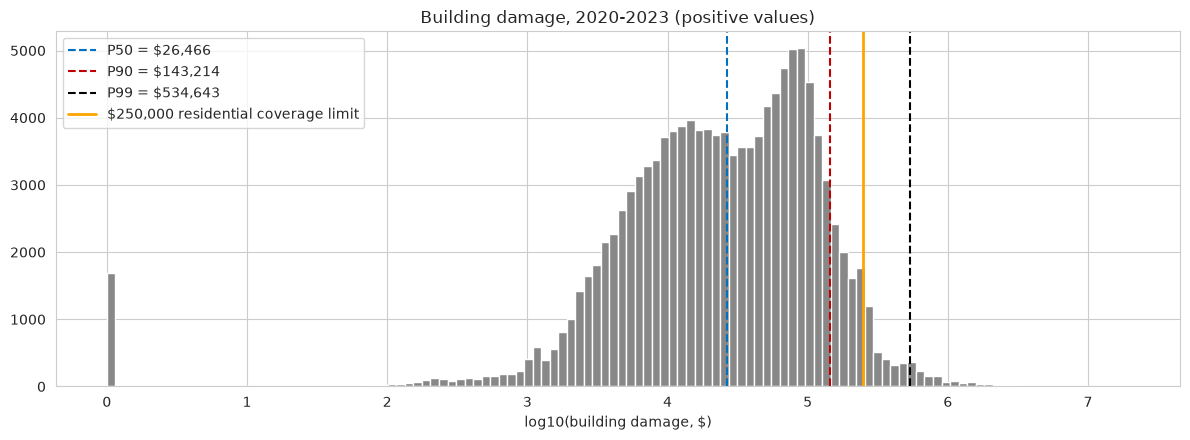

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.hist(np.log10(positive_train_damage), bins=120, color='#888888')
for p, color in [(50, '#0070C0'), (90, '#C00000'), (99, 'black')]:
    value = positive_train_damage.quantile(p / 100)
    ax.axvline(np.log10(value), color=color, ls='--', label=f'P{p} = ${value:,.0f}')
ax.axvline(np.log10(250_000), color='orange', lw=2, label='$250,000 residential coverage limit')
ax.set_xlabel('log10(building damage, $)')
ax.set_title('Building damage, 2020-2023 (positive values)')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_damage_distribution_line.png', dpi=120)
plt.show()

**Why the 90th percentile?**
1. It is the same "top 10%" idea as the `Luxury` target in Lecture 07, so the method is familiar.
2. The top 10% of claims carry a large share of all damage dollars (see the table): it is where the money is.
3. It sits below the 250,000 dollar coverage limit, so the target is not just "the house was big enough to hit the cap".
4. It is learned on the **training years only**, so the test years cannot move the line (no leakage).

**A second line from FEMA itself.** FEMA calls a building **substantially damaged** when the damage is at
least 50% of the building's market value. Then it must be rebuilt to current flood rules. We test this line
too (Section 9), with the adjuster's pre-flood value as the denominator. The denominator is only used to
build the target, never as a feature.

In [4]:
print('Large-loss rate by year (%), among claims with recorded damage:')
rate_table = damage_known.groupby('loss_year').agg(claims=('id', 'size'), large_loss_pct=('large_loss_flag', 'mean'),
                                                   substantial_damage_pct=('substantial_damage_flag', 'mean'))
rate_table[['large_loss_pct', 'substantial_damage_pct']] *= 100
print(rate_table.round(1).to_string())

Large-loss rate by year (%), among claims with recorded damage:
           claims  large_loss_pct  substantial_damage_pct
loss_year                                                
2020        27677             2.5                     6.8
2021        39697             4.9                    10.4
2022        49683            17.6                    22.3
2023        18043             5.4                    11.3
2024        88259            18.3                    23.7
2025        11103             7.3                    12.2


The rate is much higher in 2024 (Helene and Milton) than in the training years. Our model will be tested on a
year that is **worse** than anything it trained on. That is a hard but honest test.

---
# Section 2: Data for RQ2

In [5]:
TARGET = 'large_loss_flag'
damage_known[TARGET] = damage_known[TARGET].astype(int)
train_claims = damage_known[damage_known['loss_year'].isin(TRAIN_YEARS)].reset_index(drop=True)
test_claims = damage_known[damage_known['loss_year'].isin(TEST_YEARS)].reset_index(drop=True)
print(f'Train: {len(train_claims):,} claims, {train_claims[TARGET].mean() * 100:.1f}% large')
print(f'Test : {len(test_claims):,} claims, {test_claims[TARGET].mean() * 100:.1f}% large')
for set_name, (numeric, categorical) in FEATURE_SETS.items():
    check_no_leakage(numeric + categorical)
numeric_C, categorical_C = FEATURE_SETS['C. NFIP + event + context (ACS, NRI)']

Train: 135,100 claims, 9.1% large
Test : 99,362 claims, 17.1% large


---
# Section 3: Fixing Imbalance (Lecture 07, Section 12)

With about 1 positive in 10, a model can reach 90% accuracy by never flagging anything. Three standard fixes:

| Fix | What it does |
|---|---|
| **class weights** | errors on the rare class cost more in the loss function (`class_weight='balanced'`) |
| **undersampling** | train on all positives and a random subset of negatives |
| **threshold moving** | keep the model, but flag at a lower probability than 0.5 |

Important: class weights and undersampling change the **scores**, but ROC-AUC and PR-AUC only look at the
**ranking**. We therefore also report precision and recall at the default 0.5 cut.

In [6]:
def fit_lightgbm(train_rows, numeric, categorical, class_weight=None, n_estimators=600, target=TARGET):
    model = lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=0.03, num_leaves=63, min_child_samples=100,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                               class_weight=class_weight, random_state=SEED, verbose=-1)
    model.fit(to_category_frame(train_rows, numeric, categorical), train_rows[target])
    return model


def evaluate(name, y_true, scores, cut=0.5):
    predicted = (scores >= cut).astype(int)
    return {'setting': name, 'ROC_AUC': roc_auc_score(y_true, scores), 'PR_AUC': average_precision_score(y_true, scores),
            'lift_top10%': lift_at_top(y_true, scores, 0.10),
            'precision@0.5': precision_score(y_true, predicted, zero_division=0),
            'recall@0.5': recall_score(y_true, predicted)}


imbalance_rows = []
test_frame_C = to_category_frame(test_claims, numeric_C, categorical_C)
model_plain = fit_lightgbm(train_claims, numeric_C, categorical_C)
imbalance_rows.append(evaluate('no fix', test_claims[TARGET], model_plain.predict_proba(test_frame_C)[:, 1]))
model_weighted = fit_lightgbm(train_claims, numeric_C, categorical_C, class_weight='balanced')
imbalance_rows.append(evaluate('class_weight = balanced', test_claims[TARGET], model_weighted.predict_proba(test_frame_C)[:, 1]))
positives = train_claims[train_claims[TARGET] == 1]
negatives = train_claims[train_claims[TARGET] == 0].sample(len(positives) * 2, random_state=SEED)
undersampled = pd.concat([positives, negatives])
model_under = fit_lightgbm(undersampled, numeric_C, categorical_C)
imbalance_rows.append(evaluate('undersample negatives to 2:1', test_claims[TARGET], model_under.predict_proba(test_frame_C)[:, 1]))
imbalance_table = pd.DataFrame(imbalance_rows).round(4)
print(f'Random PR-AUC = positive share in test = {test_claims[TARGET].mean():.3f}')
print(imbalance_table.to_string(index=False))

Random PR-AUC = positive share in test = 0.171
                     setting  ROC_AUC  PR_AUC  lift_top10%  precision@0.5  recall@0.5
                      no fix   0.8214  0.4722       3.0473         0.7280      0.0516
     class_weight = balanced   0.8269  0.4765       3.0596         0.5393      0.2758
undersample negatives to 2:1   0.8225  0.4710       3.0803         0.5555      0.2545


The ranking metrics barely move. The precision/recall at 0.5 move a lot: the fixes mainly **shift the
threshold**. In the rest of the notebook we keep the plain model and choose the threshold on purpose
(Section 7), which is the cleanest of the three fixes.

---
# Section 4: Course Models on RQ2

In [7]:
model_rows = []
sample_train = train_claims.sample(min(60_000, len(train_claims)), random_state=SEED)
course_models = {
    'Gaussian naive Bayes': GaussianNB(),
    'Decision tree (depth 8, balanced)': DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, class_weight='balanced', random_state=SEED),
    'Logistic regression (balanced)': LogisticRegression(max_iter=3000, C=0.5, class_weight='balanced'),
    'Neural network (MLP 64-32)': MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=512, early_stopping=True,
                                                max_iter=60, random_state=SEED),
}
for model_name, estimator in course_models.items():
    pipeline = Pipeline([('prep', make_preprocessor(numeric_C, categorical_C, scale=True)), ('model', estimator)])
    training_rows = sample_train if model_name == 'Gaussian naive Bayes' else train_claims
    pipeline.fit(training_rows, training_rows[TARGET])
    model_rows.append(evaluate(model_name, test_claims[TARGET], pipeline.predict_proba(test_claims)[:, 1]))
model_rows.append(evaluate('LightGBM (no fix)', test_claims[TARGET], model_plain.predict_proba(test_frame_C)[:, 1]))
model_table = pd.DataFrame(model_rows).round(4)
model_table.to_csv(TABLE_DIR / '04_rq2_model_comparison.csv', index=False)
print(model_table.to_string(index=False))

                          setting  ROC_AUC  PR_AUC  lift_top10%  precision@0.5  recall@0.5
             Gaussian naive Bayes   0.7270  0.3163       2.1275         0.2242      0.8853
Decision tree (depth 8, balanced)   0.7680  0.3557       2.3062         0.3835      0.2461
   Logistic regression (balanced)   0.7830  0.3791       2.4254         0.3603      0.4011
       Neural network (MLP 64-32)   0.7738  0.3655       2.4095         0.5104      0.0611
                LightGBM (no fix)   0.8214  0.4722       3.0473         0.7280      0.0516


---
# Section 5: The Progression: NFIP Only vs NFIP + External Data

In [8]:
progression_rows = []
progression_scores = {}
progression_models = {}
for set_name, (numeric, categorical) in FEATURE_SETS.items():
    model = fit_lightgbm(train_claims, numeric, categorical)
    scores = model.predict_proba(to_category_frame(test_claims, numeric, categorical))[:, 1]
    progression_scores[set_name] = scores
    progression_models[set_name] = model
    logistic = Pipeline([('prep', make_preprocessor(numeric, categorical)),
                         ('model', LogisticRegression(max_iter=3000, C=0.5, class_weight='balanced'))])
    logistic.fit(train_claims, train_claims[TARGET])
    logistic_scores = logistic.predict_proba(test_claims)[:, 1]
    row = evaluate(set_name, test_claims[TARGET], scores)
    row['Logistic_PR_AUC'] = average_precision_score(test_claims[TARGET], logistic_scores)
    row['Logistic_ROC_AUC'] = roc_auc_score(test_claims[TARGET], logistic_scores)
    progression_rows.append(row)
progression_table = pd.DataFrame(progression_rows).rename(columns={'setting': 'feature_set'}).round(4)
progression_table.to_csv(TABLE_DIR / '04_rq2_progression.csv', index=False)
print(f'Test positives: {test_claims[TARGET].mean() * 100:.1f}%  (random PR-AUC)')
print(progression_table.drop(columns=['precision@0.5', 'recall@0.5']).to_string(index=False))

Test positives: 17.1%  (random PR-AUC)
                            feature_set  ROC_AUC  PR_AUC  lift_top10%  Logistic_PR_AUC  Logistic_ROC_AUC
                           A. NFIP only   0.8126  0.4121       2.5824           0.3988            0.7877
B. NFIP + event (PRISM, HURDAT2, coast)   0.8072  0.4551       2.9570           0.3767            0.7768
   C. NFIP + event + context (ACS, NRI)   0.8214  0.4722       3.0473           0.3791            0.7830


## 5.1 Event-grouped cross-validation (2020-2023)

In [9]:
group_cv = GroupKFold(n_splits=5)
cv_rows = []
for set_name in FEATURE_SETS:
    numeric, categorical = FEATURE_SETS[set_name]
    fold_pr, fold_roc = [], []
    for fit_index, validation_index in group_cv.split(train_claims, groups=train_claims['event_group']):
        fit_rows, validation_rows = train_claims.iloc[fit_index], train_claims.iloc[validation_index]
        model = fit_lightgbm(fit_rows, numeric, categorical, n_estimators=300)
        scores = model.predict_proba(to_category_frame(validation_rows, numeric, categorical))[:, 1]
        fold_pr.append(average_precision_score(validation_rows[TARGET], scores) / validation_rows[TARGET].mean())
        fold_roc.append(roc_auc_score(validation_rows[TARGET], scores))
    cv_rows.append({'feature_set': set_name, 'ROC_AUC_mean': np.mean(fold_roc), 'ROC_AUC_std': np.std(fold_roc),
                    'PR_AUC_over_random_mean': np.mean(fold_pr)})
cv_table = pd.DataFrame(cv_rows).round(3)
cv_table.to_csv(TABLE_DIR / '04_rq2_event_grouped_cv.csv', index=False)
print('PR_AUC_over_random = PR-AUC divided by the positive share of that fold (1.0 = random)')
print(cv_table.to_string(index=False))

PR_AUC_over_random = PR-AUC divided by the positive share of that fold (1.0 = random)
                            feature_set  ROC_AUC_mean  ROC_AUC_std  PR_AUC_over_random_mean
                           A. NFIP only         0.826        0.031                    5.199
B. NFIP + event (PRISM, HURDAT2, coast)         0.838        0.035                    5.992
   C. NFIP + event + context (ACS, NRI)         0.843        0.033                    6.038


---
# Section 6: Reproducing and Extending a Published Finding

**Published claim (Ghaedi et al. style two-stage study, PMC9348728, 2022):** flood-intensity variables are the
most important predictors of NFIP claims, and **state-level models beat a national model**.

We test both on our data:
1. Share of SHAP importance from the event (intensity) features.
2. For Florida (the state with the most claims), compare the national model with a Florida-only model,
   both scored on Florida's 2024-2025 claims.

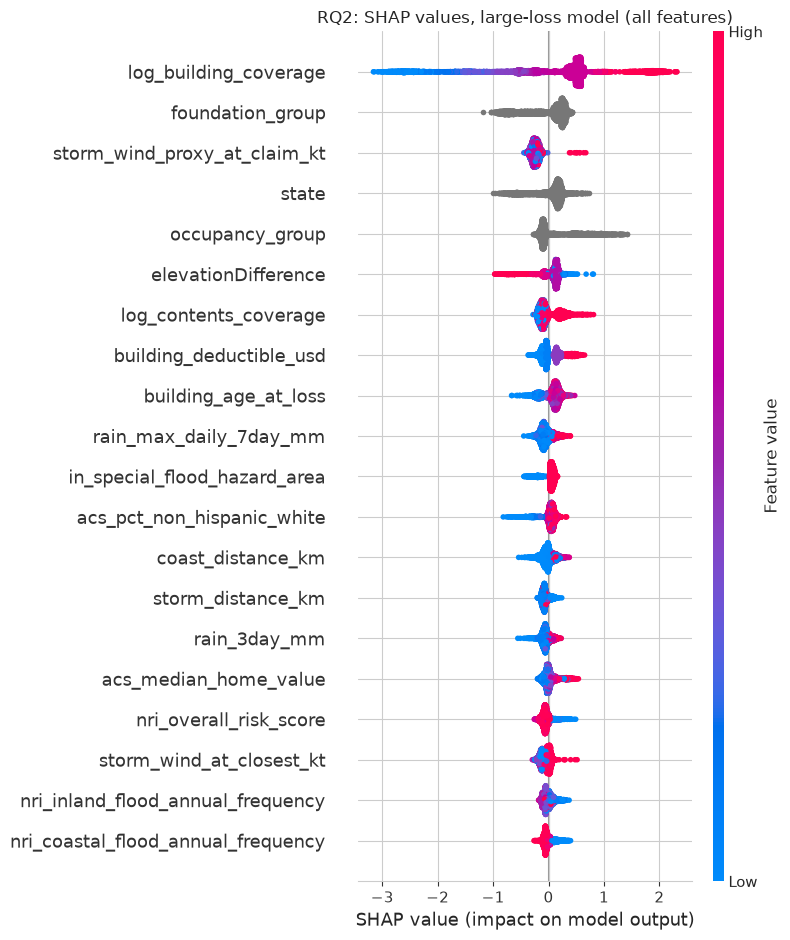

Mean |SHAP| share by data source (%):
NFIP       62.9
context    18.3
event      18.8


In [10]:
model_C = progression_models['C. NFIP + event + context (ACS, NRI)']
shap_rows = to_category_frame(test_claims.sample(5000, random_state=SEED), numeric_C, categorical_C)
shap_values = shap.TreeExplainer(model_C).shap_values(shap_rows)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
shap.summary_plot(shap_values, shap_rows, max_display=20, show=False)
plt.title('RQ2: SHAP values, large-loss model (all features)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_rq2_shap_summary.png', dpi=110)
plt.show()
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_rows.columns).sort_values(ascending=False)
source_of = lambda c: 'NFIP' if c in NFIP_NUMERIC_FEATURES + NFIP_CATEGORICAL_FEATURES else 'event' if c in EVENT_FEATURES else 'context'
shap_share = shap_importance.groupby(source_of).sum()
print('Mean |SHAP| share by data source (%):')
print((shap_share / shap_share.sum() * 100).round(1).to_string())
shap_importance.round(4).to_csv(TABLE_DIR / '04_rq2_shap_importance.csv')

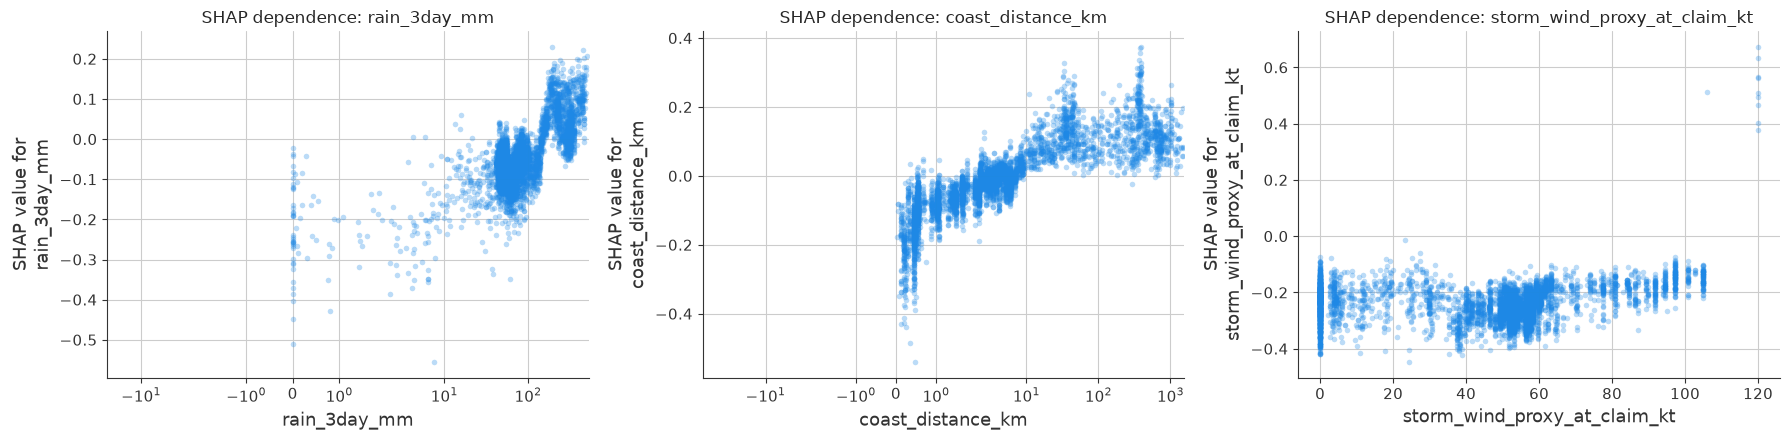

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, feature in zip(axes, ['rain_3day_mm', 'coast_distance_km', 'storm_wind_proxy_at_claim_kt']):
    shap.dependence_plot(feature, shap_values, shap_rows, interaction_index=None, ax=ax, show=False, alpha=0.3)
    if feature != 'storm_wind_proxy_at_claim_kt':
        ax.set_xscale('symlog')
    ax.set_title(f'SHAP dependence: {feature}')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_rq2_shap_dependence.png', dpi=110)
plt.show()

In [12]:
state_rows = []
for state in ['FL', 'LA', 'TX', 'NC']:
    state_train = train_claims[train_claims['state'] == state]
    state_test = test_claims[test_claims['state'] == state]
    if state_test[TARGET].sum() < 30 or state_train[TARGET].sum() < 30:
        continue
    numeric_no_state = numeric_C
    categorical_no_state = [c for c in categorical_C if c != 'state']
    state_model = fit_lightgbm(state_train, numeric_no_state, categorical_no_state, n_estimators=400)
    state_scores = state_model.predict_proba(to_category_frame(state_test, numeric_no_state, categorical_no_state))[:, 1]
    national_scores = model_C.predict_proba(to_category_frame(state_test, numeric_C, categorical_C))[:, 1]
    state_rows.append({'state': state, 'train_claims': len(state_train), 'test_claims': len(state_test),
                       'test_large_%': state_test[TARGET].mean() * 100,
                       'national_model_PR_AUC': average_precision_score(state_test[TARGET], national_scores),
                       'state_model_PR_AUC': average_precision_score(state_test[TARGET], state_scores),
                       'national_ROC_AUC': roc_auc_score(state_test[TARGET], national_scores),
                       'state_ROC_AUC': roc_auc_score(state_test[TARGET], state_scores)})
state_table = pd.DataFrame(state_rows).round(3)
state_table.to_csv(TABLE_DIR / '04_rq2_state_vs_national.csv', index=False)
print(state_table.to_string(index=False))

state  train_claims  test_claims  test_large_%  national_model_PR_AUC  state_model_PR_AUC  national_ROC_AUC  state_ROC_AUC
   FL         59551        70421        21.258                  0.493               0.482             0.790          0.782
   LA         21146         3041         2.861                  0.287               0.242             0.899          0.870
   TX          4187         6026         5.526                  0.259               0.197             0.866          0.818
   NC          2577         3618        16.473                  0.496               0.450             0.807          0.762


**Reading the comparison.** Ghaedi et al. (2022) found that state models beat the national model. **We do not
reproduce this.** In all four states the national model has the higher PR-AUC (FL 0.493 vs 0.482, LA 0.287 vs 0.242,
TX 0.259 vs 0.197, NC 0.496 vs 0.450) and the higher ROC-AUC. Our setting is different: claim level instead of
county-event level, and a time split. Our state training sets are small (TX 4,187 claims, NC 2,577), and the national
model borrows strength from other storms. The other half of their finding, that flood-intensity features matter, holds:
rain and storm features are 18.8% of the mean |SHAP| (cell above), and adding them raises PR-AUC.

---
# Section 7: Turning Scores into Flags (Lecture 07, Section 8)

Suppose the program can send its senior adjusters to the **top 10%** of new claims by score. We set the
threshold so that 10% of the **2023 validation** claims are flagged, then apply it to 2024-2025.

Threshold (top 10% of 2023 scores): 0.038
Share of 2024-2025 claims flagged : 15.3%
Precision: 0.404   Recall: 0.362   F1: 0.382


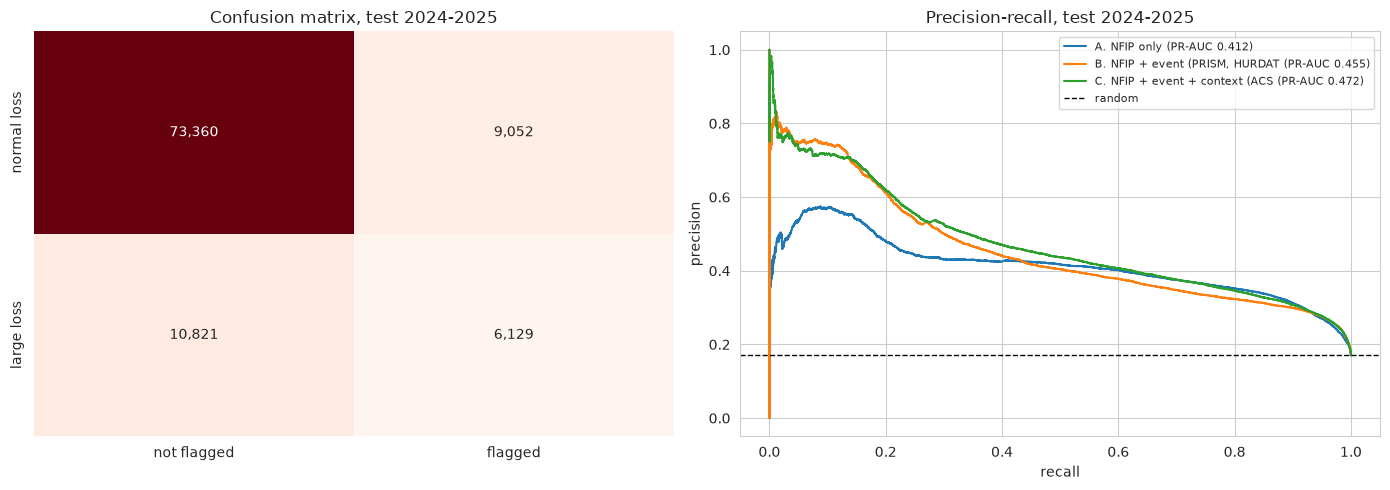

In [13]:
fit_rows = train_claims[train_claims['loss_year'] <= 2022]
validation_rows = train_claims[train_claims['loss_year'] == 2023]
flag_model = fit_lightgbm(fit_rows, numeric_C, categorical_C)
validation_scores = flag_model.predict_proba(to_category_frame(validation_rows, numeric_C, categorical_C))[:, 1]
flag_threshold = float(np.quantile(validation_scores, 0.90))
test_scores = flag_model.predict_proba(test_frame_C)[:, 1]
test_flags = (test_scores >= flag_threshold).astype(int)
print(f'Threshold (top 10% of 2023 scores): {flag_threshold:.3f}')
print(f'Share of 2024-2025 claims flagged : {test_flags.mean() * 100:.1f}%')
print(f'Precision: {precision_score(test_claims[TARGET], test_flags):.3f}   Recall: {recall_score(test_claims[TARGET], test_flags):.3f}   '
      f'F1: {f1_score(test_claims[TARGET], test_flags):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_matrix(test_claims[TARGET], test_flags), annot=True, fmt=',', cmap='Reds', cbar=False, ax=axes[0],
            xticklabels=['not flagged', 'flagged'], yticklabels=['normal loss', 'large loss'])
axes[0].set_title('Confusion matrix, test 2024-2025')
for set_name, scores in progression_scores.items():
    precision, recall, _ = precision_recall_curve(test_claims[TARGET], scores)
    axes[1].plot(recall, precision, label=f'{set_name[:30]} (PR-AUC {average_precision_score(test_claims[TARGET], scores):.3f})')
axes[1].axhline(test_claims[TARGET].mean(), color='k', ls='--', lw=1, label='random')
axes[1].set_xlabel('recall')
axes[1].set_ylabel('precision')
axes[1].set_title('Precision-recall, test 2024-2025')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_rq2_confusion_pr.png', dpi=120)
plt.show()

**Why recall looks low and is still useful.** 2024 had far more large losses than 2023, so flagging 10% of
claims cannot catch most of them. Read precision instead: among the flagged claims, the share that are truly
large is several times the base rate. Look at recall when more claims can be flagged:

In [14]:
capacity_rows = []
for share in [0.05, 0.10, 0.20, 0.30, 0.40]:
    cut = np.quantile(test_scores, 1 - share)
    flagged = test_scores >= cut
    capacity_rows.append({'flag top share': f'{share * 100:.0f}%', 'precision': test_claims[TARGET][flagged].mean(),
                          'recall': test_claims[TARGET][flagged].sum() / test_claims[TARGET].sum(),
                          'lift': test_claims[TARGET][flagged].mean() / test_claims[TARGET].mean()})
print(pd.DataFrame(capacity_rows).round(3).to_string(index=False))

flag top share  precision  recall  lift
            5%      0.577   0.169 3.382
           10%      0.466   0.273 2.734
           20%      0.380   0.445 2.226
           30%      0.333   0.586 1.953
           40%      0.302   0.708 1.770


---
# Section 8: Per-Event Performance

In [15]:
test_claims['rq2_score'] = progression_scores['C. NFIP + event + context (ACS, NRI)']
test_claims['rq2_score_nfip_only'] = progression_scores['A. NFIP only']
per_event = []
for event, group in test_claims.groupby('event_group'):
    if len(group) < 500 or group[TARGET].nunique() < 2:
        continue
    per_event.append({'event': event, 'claims': len(group), 'large_%': group[TARGET].mean() * 100,
                      'ROC_AUC_NFIP_only': roc_auc_score(group[TARGET], group['rq2_score_nfip_only']),
                      'ROC_AUC_all_features': roc_auc_score(group[TARGET], group['rq2_score'])})
per_event_table = pd.DataFrame(per_event).sort_values('claims', ascending=False).round(3)
print(per_event_table.to_string(index=False))

                            event  claims  large_%  ROC_AUC_NFIP_only  ROC_AUC_all_features
                 Hurricane Helene   52282   26.064              0.778                 0.799
                 Hurricane Milton   17586    9.104              0.753                 0.785
              no_named_event_2024    8630    4.056              0.833                 0.867
              no_named_event_2025    5435    5.557              0.806                 0.829
                  Hurricane Debby    2105    6.413              0.764                 0.778
                  Hurricane Beryl    2010    2.189              0.941                 0.950
      Central U.S. April Flooding    1944    8.076              0.819                 0.855
               Hurricane Francine    1916    2.244              0.905                 0.918
      June South Florida Flooding    1272    9.591              0.826                 0.824
            Texas Spring Flooding     965    9.948              0.759           

Inside one storm, rain and wind vary less, so the external features help less **within** an event than
**between** events. Building and location facts (elevation, foundation, coast distance) do the work inside a storm.

---
# Section 9: Sensitivity: Other Lines

Does the answer depend on where we put the line?

In [16]:
sensitivity_rows = []
p95_line = positive_train_damage.quantile(0.95)
p75_line = positive_train_damage.quantile(0.75)
targets = {
    f'damage > P75 (${p75_line:,.0f})': (damage_known['buildingDamageAmount'] > p75_line).astype(float),
    f'damage > P90 (${large_loss_line:,.0f}) [main]': damage_known[TARGET].astype(float),
    f'damage > P95 (${p95_line:,.0f})': (damage_known['buildingDamageAmount'] > p95_line).astype(float),
    'substantial damage (damage >= 50% of value)': damage_known['substantial_damage_flag'],
}
for target_name, target_values in targets.items():
    data = damage_known.assign(alternative_target=target_values).dropna(subset=['alternative_target'])
    data['alternative_target'] = data['alternative_target'].astype(int)
    train_rows = data[data['loss_year'].isin(TRAIN_YEARS)]
    test_rows = data[data['loss_year'].isin(TEST_YEARS)]
    for set_name in ['A. NFIP only', 'C. NFIP + event + context (ACS, NRI)']:
        numeric, categorical = FEATURE_SETS[set_name]
        model = fit_lightgbm(train_rows, numeric, categorical, n_estimators=400, target='alternative_target')
        scores = model.predict_proba(to_category_frame(test_rows, numeric, categorical))[:, 1]
        sensitivity_rows.append({'target': target_name, 'feature_set': set_name[:2],
                                 'test_positive_%': test_rows['alternative_target'].mean() * 100,
                                 'ROC_AUC': roc_auc_score(test_rows['alternative_target'], scores),
                                 'PR_AUC': average_precision_score(test_rows['alternative_target'], scores),
                                 'lift_top10%': lift_at_top(test_rows['alternative_target'], scores)})
# Sensitivity only: what if we accepted the (leak-suspect) replacement cost as a pre-loss rating variable?
numeric_with_cost = numeric_C + ['log_replacement_cost', 'coverage_to_replacement_ratio']
model_with_cost = fit_lightgbm(train_claims, numeric_with_cost, categorical_C, n_estimators=400)
scores_with_cost = model_with_cost.predict_proba(to_category_frame(test_claims, numeric_with_cost, categorical_C))[:, 1]
sensitivity_rows.append({'target': f'damage > P90 [main], C + replacement cost (NOT used, leak-suspect)', 'feature_set': 'C+',
                         'test_positive_%': test_claims[TARGET].mean() * 100,
                         'ROC_AUC': roc_auc_score(test_claims[TARGET], scores_with_cost),
                         'PR_AUC': average_precision_score(test_claims[TARGET], scores_with_cost),
                         'lift_top10%': lift_at_top(test_claims[TARGET], scores_with_cost)})
sensitivity_table = pd.DataFrame(sensitivity_rows).round(3)
sensitivity_table.to_csv(TABLE_DIR / '04_rq2_sensitivity.csv', index=False)
print(sensitivity_table.to_string(index=False))

                                                            target feature_set  test_positive_%  ROC_AUC  PR_AUC  lift_top10%
                                            damage > P75 ($77,886)          A.           40.048    0.836   0.714        1.901
                                            damage > P75 ($77,886)          C.           40.048    0.847   0.735        1.965
                                    damage > P90 ($143,214) [main]          A.           17.059    0.813   0.412        2.549
                                    damage > P90 ($143,214) [main]          C.           17.059    0.818   0.467        3.000
                                           damage > P95 ($216,886)          A.            7.170    0.833   0.282        4.126
                                           damage > P95 ($216,886)          C.            7.170    0.847   0.363        4.763
                       substantial damage (damage >= 50% of value)          A.           22.406    0.774   0.412      

In [17]:
results_rq2 = {'large_loss_line_usd': large_loss_line, 'progression': progression_table.to_dict('records'),
               'event_grouped_cv': cv_table.to_dict('records'), 'flag_threshold': flag_threshold,
               'state_vs_national': state_table.to_dict('records'), 'sensitivity': sensitivity_table.to_dict('records')}
json.dump(results_rq2, open(TABLE_DIR / '04_rq2_results.json', 'w'), indent=2, default=float)

---
# Research Question -> Answer

> **RQ2. Can we flag claims whose damage is above a "large loss" line, using only facts known about the
> building, policy and storm?**

**Line.** 90th percentile of positive building damage in 2020-2023 (value printed at the top), justified by
Lecture 07's top-10% target, by the share of damage dollars above it, and by staying below the coverage cap.

**Answer: yes, as a ranking tool. Building and policy facts already carry most of the signal; storm and rain data
make the flag sharper.** (Test = 2024-2025, 99,362 claims with damage, 17.1% large; a random model has PR-AUC 0.171.)

| LightGBM | NFIP only (A) | + event (B) | + context (C) |
|---|---|---|---|
| ROC-AUC, time split | 0.813 | 0.807 | **0.821** |
| PR-AUC, time split | 0.412 | 0.455 | **0.472** |
| Lift in the top 10% | 2.58 | 2.96 | **3.05** |
| Event-grouped CV ROC-AUC (2020-23) | 0.826 | 0.838 | 0.843 |

- **NFIP-only is already good at ranking** (ROC 0.81): coverage and building facts (63% of the mean |SHAP|) describe how
  much there is to lose. This is different from RQ1, where NFIP-only was weak.
- **External data improves the part that matters for a flag:** PR-AUC rises from 0.41 to 0.47 and the top-10% lift
  from 2.6 to 3.0. The gain is clearest for the rarest line (P95: PR-AUC 0.28 to 0.36). It is also visible within
  storms: all features beat NFIP-only for 11 of the 14 largest 2024-2025 events (one tie).
- **Operating point:** a threshold set to flag 10% of the 2023 claims flags 15.3% of the 2024-2025 claims (a
  more severe period). Precision is 0.40 and recall 0.36. Flagging the top 20% catches 44.5% of the large losses
  with precision 0.38 (2.2 times the base rate).
- **Course models:** LightGBM (PR-AUC 0.472) beats logistic regression (0.379), the MLP (0.366), the tree (0.356)
  and naive Bayes (0.316). Class weights barely change the ranking (PR-AUC 0.477 vs 0.472) but move the 0.5
  threshold. That is why we set the threshold on 2023 instead.
- **Robust to the line:** P75, P95 and FEMA's substantial-damage rule give the same picture.
- **Leakage check:** adding the leak-suspect replacement cost would raise PR-AUC to 0.566. This shows how easy it is
  to report an inflated result. We do not use it.
- **Published findings:** flood-intensity features matter (reproduced). State models beat national (not reproduced
  at claim level).